# Notebook 02: Heuristic Method and Results

**Delivery Optimization (Capacitated Vehicle Routing Problem)**
IT50802 Optimization Methods, MSc in AI, SLIIT

Owner: **U.D.L.L De Silva (MS26903224)** · Group member: M.Z.M. Ruzbihan (MS26911458)

This notebook covers:

1. the greedy nearest-neighbour heuristic,
2. simulated annealing (SA): moves, acceptance rule and cooling,
3. a live SA run on a small instance (compared with the proven optimum) and on all 87 customers,
4. the results of all experiments (E1–E5), read from `results/tables/`.

All logic lives in `src/`. The experiment tables are produced by `python -m src.run_comparison`
(E1, E2) and `python -m src.run_heuristic_analysis` (E3–E5). This notebook only reads them; it does not re-run them.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import math
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src.data_prep import depot_location, load_customers, make_instance, sample_instance
from src.evaluate import check_feasible, make_toy_instance, summarize
from src.heuristics import SA_ITERATIONS, nearest_neighbour, solve_greedy, solve_sa
from src.plots import STYLE, draw_routes

TABLES = REPO_ROOT / "results" / "tables"
FIGURES = REPO_ROOT / "results" / "figures"
pd.set_option("display.width", 140)
customers = load_customers()

## 1. Greedy nearest-neighbour

1. Start a van at the depot with an empty load.
2. Drive to the **nearest** unvisited customer whose order still fits ($\text{load} + q_j \le Q$).
3. When nothing fits, return to the depot and start a new van.

It is very fast and always feasible, but **short-sighted**: each step only looks one stop ahead.

**Hand check (toy instance, $Q = 100$ kg).** Depot at (0,0); customers 1 (3,0) 40 kg, 2 (3,4) 30 kg, 3 (0,4) 20 kg, 4 (6,0) 50 kg.
From 0 the nearest is 1 (3 units, load 40), then 4 (3 units, load 90). Nothing else fits, so the van returns: 3 + 3 + 6 = 12.
The second van visits 3 then 2: 4 + 3 + 5 = 12. **Total = 24.**

In [2]:
toy = make_toy_instance()
toy_routes = nearest_neighbour(toy)
print("Greedy routes:", toy_routes)
print("Total distance:", summarize(toy_routes, toy)["distance_km"], "(hand calculation: 24)")
print("Feasibility problems:", check_feasible(toy_routes, toy))

Greedy routes: [[0, 1, 4, 0], [0, 3, 2, 0]]
Total distance: 24.0 (hand calculation: 24)
Feasibility problems: []


## 2. Simulated annealing

SA starts from the greedy plan and repeats, for a fixed number of iterations:

| Step | What happens | Code (`src/heuristics.py`) |
|---|---|---|
| Move | Pick one random change: **relocate** a customer, **swap** two customers, or **2-opt** (reverse part of a route) | `random_move()` |
| Feasibility | Reject the move if any van would exceed $Q$ | `fits_capacity()` |
| Change in cost | $\Delta = $ new distance $-$ current distance (only the changed routes are recomputed) | `delta_of()` |
| Acceptance | Accept if $\Delta \le 0$; otherwise accept with probability $e^{-\Delta/T}$ | Metropolis rule in `simulated_annealing()` |
| Cooling | $T_{k+1} = \alpha \, T_k$, falling from $T_0$ to $T_0/1000$ over the run | `cooling = final_temp_ratio ** (1 / iterations)` |
| Memory | Keep the best plan ever seen | `best_routes` |

**Starting temperature.** $T_0$ is chosen so that, at the start, an average worse move is accepted with probability 0.5:
$e^{-\bar\Delta / T_0} = 0.5 \Rightarrow T_0 = -\bar\Delta / \ln 0.5$.

**Why accept worse moves?** A plan where no single small change helps is a *local optimum*. Plain hill-climbing stops there.
Accepting some worse moves early lets SA climb out and explore; as $T$ falls it becomes greedy and settles down.

**Reproducibility.** Each run uses its own random generator `random.Random(seed)`, so the same seed always gives the same plan.

In [3]:
# How likely is SA to accept a move that makes the plan 10 km longer?
delta = 10.0
for temperature in (124.8, 50, 10, 1, 0.12):
    print(f"T = {temperature:6.2f}  ->  P(accept a +10 km move) = {math.exp(-delta / temperature):.5f}")
print(f"\nIterations per SA run: {SA_ITERATIONS:,}")

T = 124.80  ->  P(accept a +10 km move) = 0.92300
T =  50.00  ->  P(accept a +10 km move) = 0.81873
T =  10.00  ->  P(accept a +10 km move) = 0.36788
T =   1.00  ->  P(accept a +10 km move) = 0.00005
T =   0.12  ->  P(accept a +10 km move) = 0.00000

Iterations per SA run: 1,000,000


### Live run 1: a small instance with a proven optimum

Notebook 01 proved with the ILP that the optimum of instance `n10_seed3` with $Q = 600$ kg is **557.91 km**.

In [4]:
small = sample_instance(customers, n=10, seed=3, capacity=600)
greedy_small = solve_greedy(small)
sa_small = solve_sa(small, seed=0)
print(f"Greedy: {greedy_small['distance_km']:.2f} km")
print(f"SA:     {sa_small['distance_km']:.2f} km in {sa_small['runtime_s']:.1f} s (proven optimum: 557.91 km)")
print("SA feasibility problems:", check_feasible(sa_small["routes"], small))

Greedy: 803.71 km
SA:     557.91 km in 26.4 s (proven optimum: 557.91 km)
SA feasibility problems: []


### Live run 2: all 87 customers, $Q = 1{,}000$ kg

In [5]:
full = make_instance(customers, depot_location(customers), name="all_87")
greedy_full = solve_greedy(full)
sa_full = solve_sa(full, seed=0)
improvement = 100 * (greedy_full["distance_km"] - sa_full["distance_km"]) / greedy_full["distance_km"]
print(f"Greedy: {greedy_full['distance_km']:.2f} km with {len(greedy_full['routes'])} vans")
print(f"SA:     {sa_full['distance_km']:.2f} km with {len(sa_full['routes'])} vans in {sa_full['runtime_s']:.1f} s "
      f"(T0 = {sa_full['start_temperature']:.1f})")
print(f"SA is {improvement:.1f} % shorter than greedy")
print("Shared checker:", summarize(sa_full["routes"], full))

Greedy: 3002.94 km with 11 vans
SA:     1837.66 km with 11 vans in 19.8 s (T0 = 124.8)
SA is 38.8 % shorter than greedy
Shared checker: {'distance_km': 1837.6586070874773, 'n_routes': 11, 'min_routes_needed': 11, 'max_load_kg': 999.2, 'feasible': True, 'n_problems': 0, 'max_volume_dm3': 564.1}


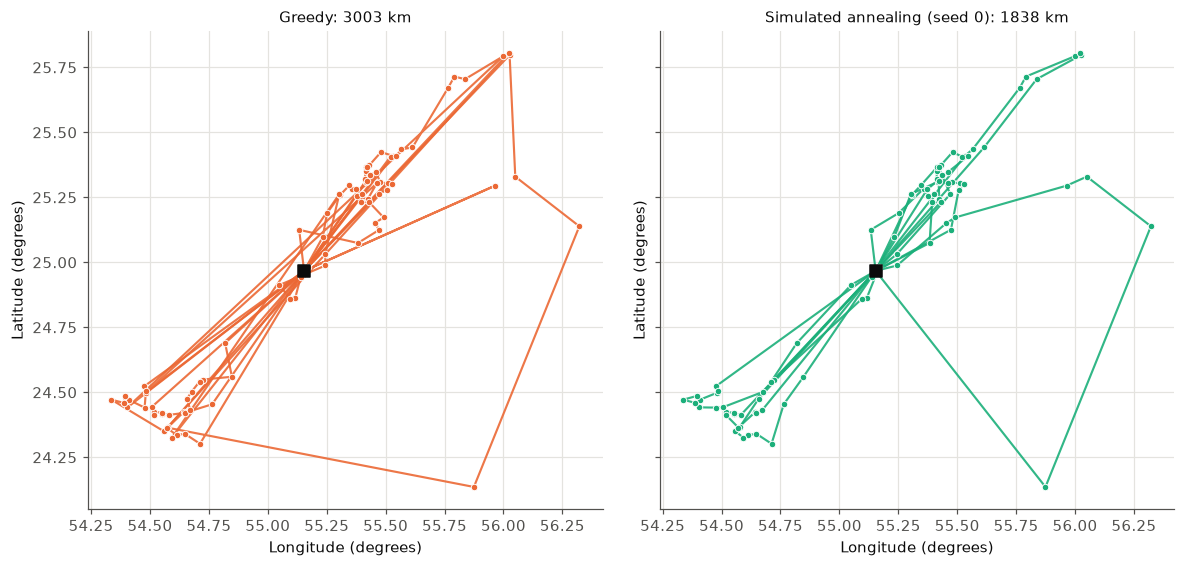

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
draw_routes(axes[0], full, greedy_full["routes"], STYLE["Greedy"]["color"],
            f"Greedy: {greedy_full['distance_km']:.0f} km")
draw_routes(axes[1], full, sa_full["routes"], STYLE["SA"]["color"],
            f"Simulated annealing (seed 0): {sa_full['distance_km']:.0f} km")
fig.tight_layout()
plt.show()

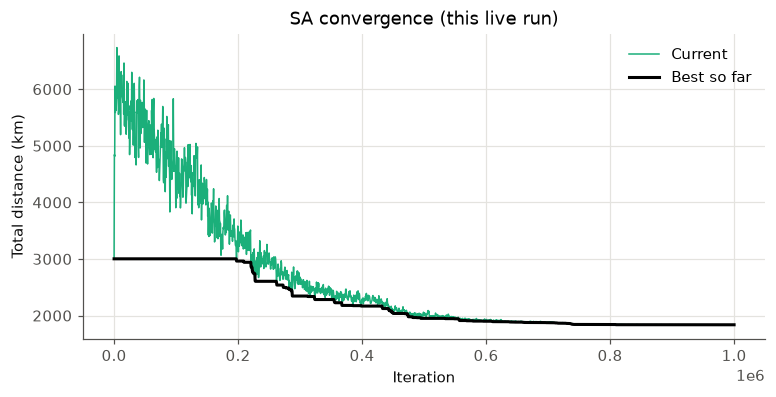

In [7]:
history = pd.DataFrame(sa_full["history"], columns=["iteration", "temperature", "current", "best"])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(history["iteration"], history["current"], color=STYLE["SA"]["color"], linewidth=1, label="Current")
ax.plot(history["iteration"], history["best"], color="black", linewidth=2, label="Best so far")
ax.set_xlabel("Iteration")
ax.set_ylabel("Total distance (km)")
ax.set_title("SA convergence (this live run)")
ax.legend()
plt.show()

## 3. Results of all experiments

The tables below are read from `results/tables/`. E1 and E2 were run on M1's laptop and E3–E5 on M2's laptop;
the machine details are in `environment.txt` and `environment_e3_e5.txt`. Distances are identical on both machines
(same seeds); runtimes depend on the machine.

### E1: small instances, compared with the proven optimum

In [8]:
e1 = pd.read_csv(TABLES / "e1_summary.csv")
e1_view = e1[["instance", "ilp_km", "ilp_time_s", "greedy_km", "greedy_gap_to_opt_pct",
              "sa_mean_km", "sa_mean_gap_to_opt_pct", "sa_runs_at_optimum", "sa_mean_time_s"]].copy()
e1_view["sa_mean_gap_to_opt_pct"] = e1_view["sa_mean_gap_to_opt_pct"].clip(lower=0)
display(e1_view.round(2))
print(f"SA runs at the proven optimum: {int(e1['sa_runs_at_optimum'].sum())} of {10 * len(e1)}")
print(f"Greedy gap to optimum: {e1['greedy_gap_to_opt_pct'].min():.1f} % to {e1['greedy_gap_to_opt_pct'].max():.1f} %")

,instance,ilp_km,ilp_time_s,greedy_km,greedy_gap_to_opt_pct,sa_mean_km,sa_mean_gap_to_opt_pct,sa_runs_at_optimum,sa_mean_time_s
0,n5_seed1,279.02,0.08,279.38,0.13,279.02,0.0,10,8.58
1,n5_seed2,296.05,0.08,322.77,9.02,296.05,0.0,10,8.59
2,n5_seed3,280.43,0.10,280.78,0.13,280.43,0.0,10,8.47
3,n8_seed1,334.57,0.35,339.59,1.50,334.57,0.0,10,10.43
4,n8_seed2,300.69,0.52,492.82,63.90,300.69,0.0,10,9.66
5,n8_seed3,285.95,0.22,301.18,5.33,285.95,0.0,10,10.36
6,n10_seed1,405.74,2.36,596.90,47.11,405.74,0.0,10,9.94
7,n10_seed2,307.30,1.56,594.82,93.56,307.30,0.0,10,9.60
8,n10_seed3,450.41,3.40,601.76,33.60,450.41,0.0,10,10.22
9,n12_seed1,339.33,7.02,498.23,46.83,339.33,0.0,10,11.58


SA runs at the proven optimum: 120 of 120
Greedy gap to optimum: 0.1 % to 93.6 %


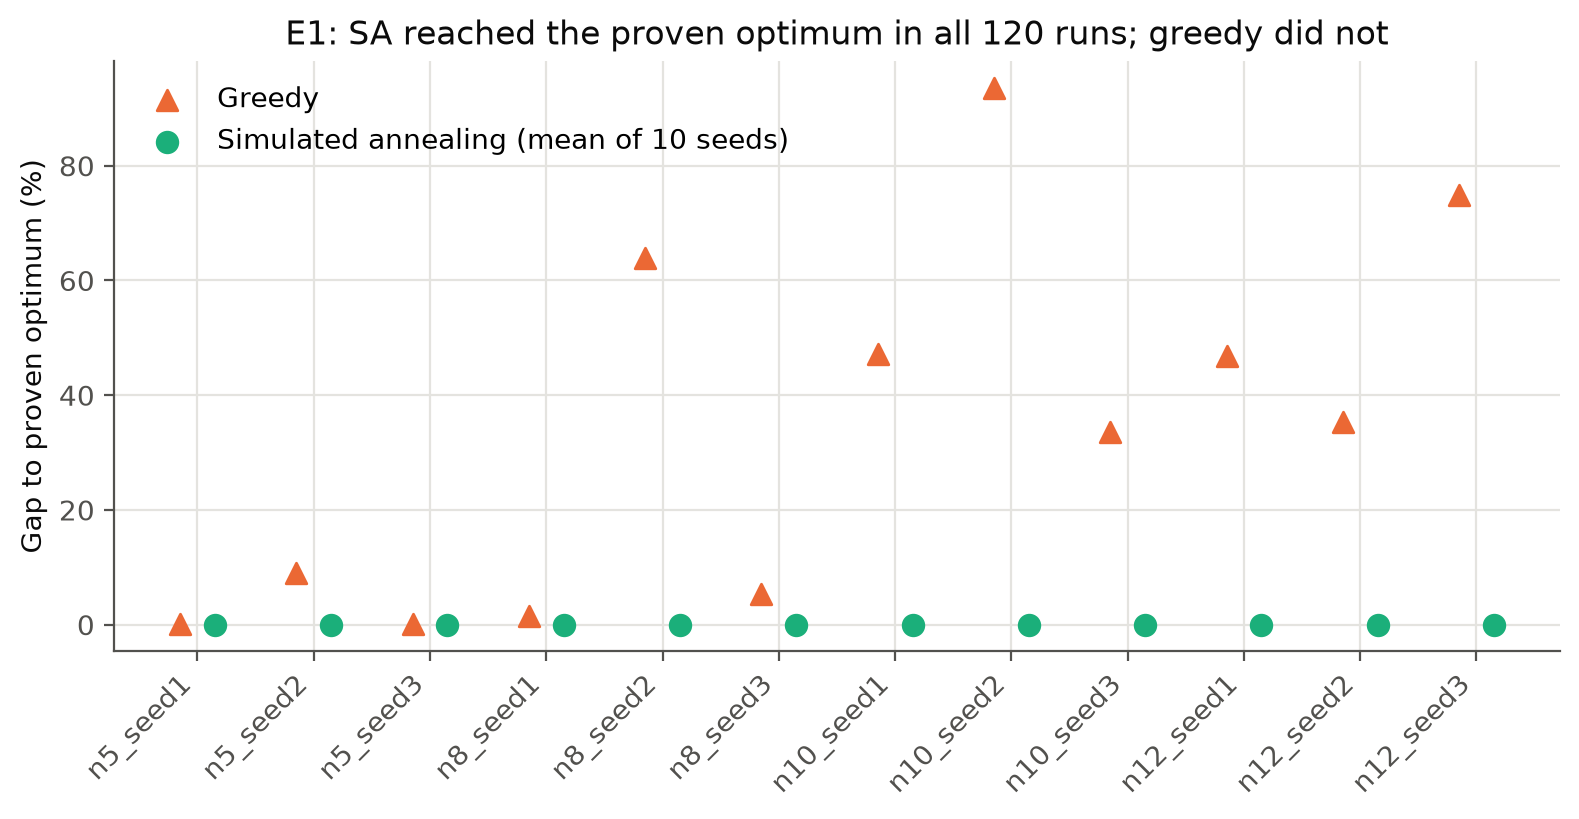

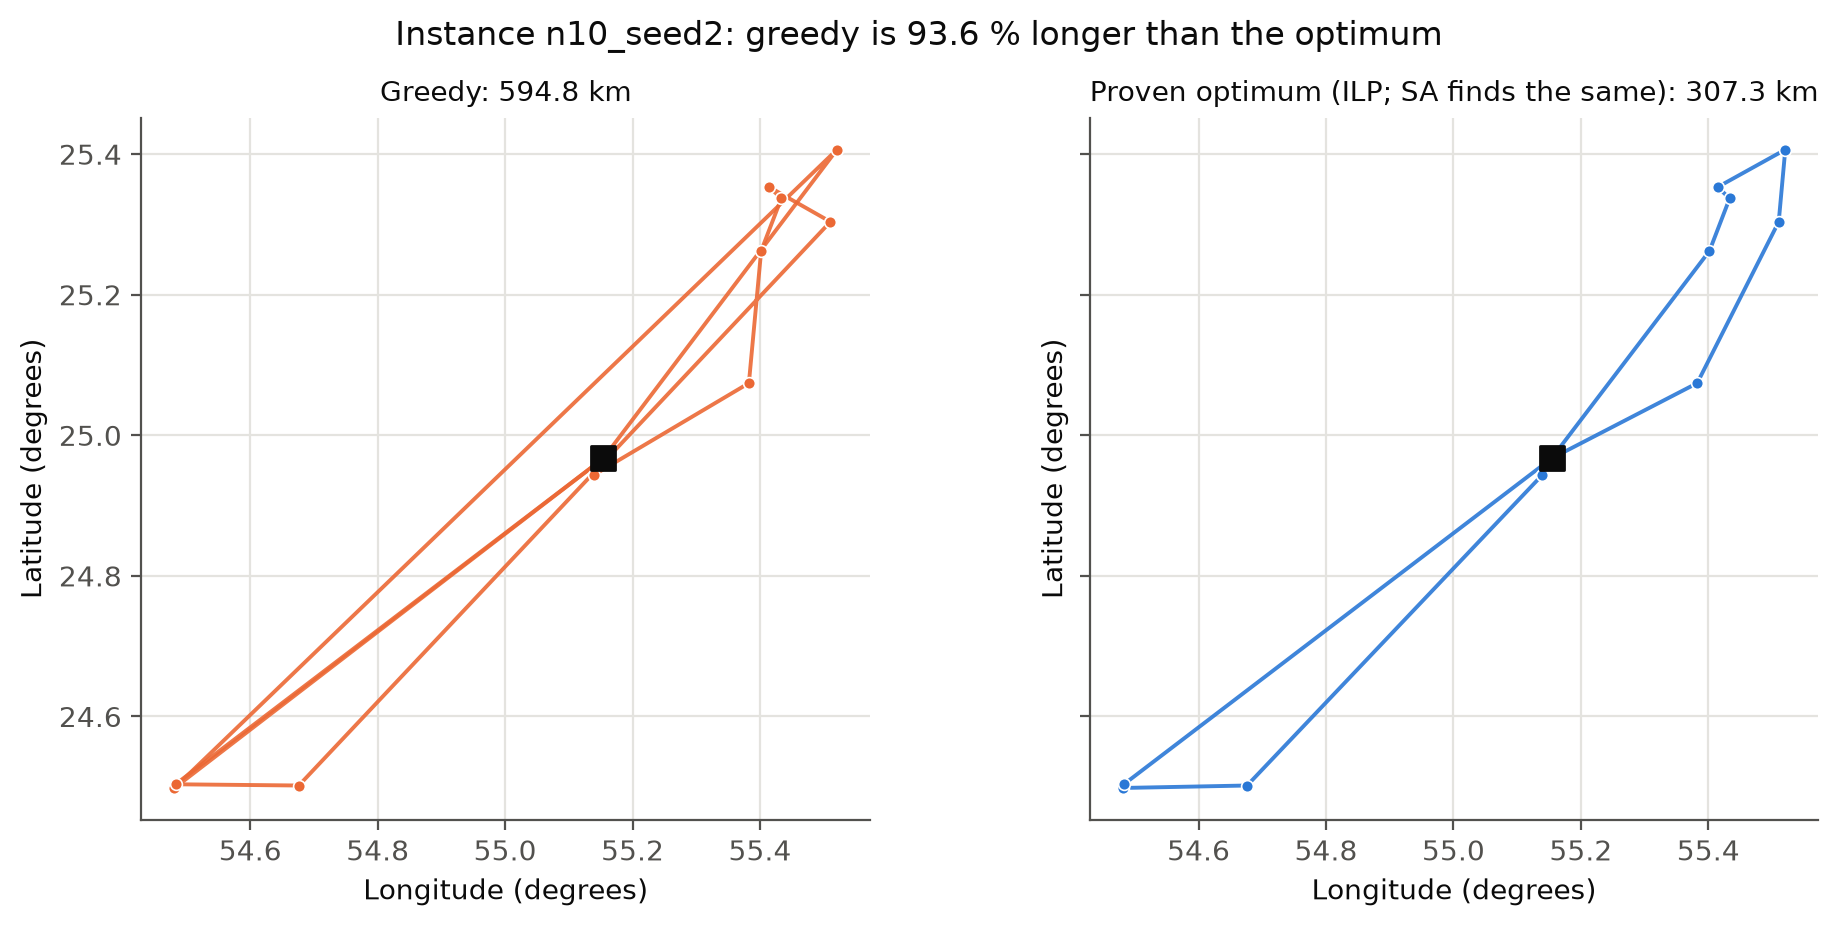

In [9]:
display(Image(FIGURES / "f6_gap_to_optimum.png", width=750))
display(Image(FIGURES / "f3_greedy_vs_optimal_routes.png", width=850))

### E2: scalability (ILP limited to 300 s)

,instance,ilp_status,ilp_km,ilp_lower_bound_km,ilp_time_s,greedy_km,sa_mean_km,sa_best_km,sa_mean_time_s
0,n15_seed1,feasible,494.50,399.34,300.18,663.37,494.23,494.23,10.58
1,n20_seed1,feasible,430.86,245.75,300.24,671.63,412.77,412.77,9.81
2,n30_seed1,feasible,1342.71,414.06,299.51,1397.26,864.26,862.47,10.20
3,n45_seed1,feasible,1585.10,406.70,297.53,1871.55,1001.07,998.77,9.07
4,n60_seed1,feasible,2054.38,499.02,300.24,2381.81,1307.85,1291.55,8.88
5,n87_seed1,feasible,3234.35,673.48,300.33,3002.94,1859.73,1837.66,8.87


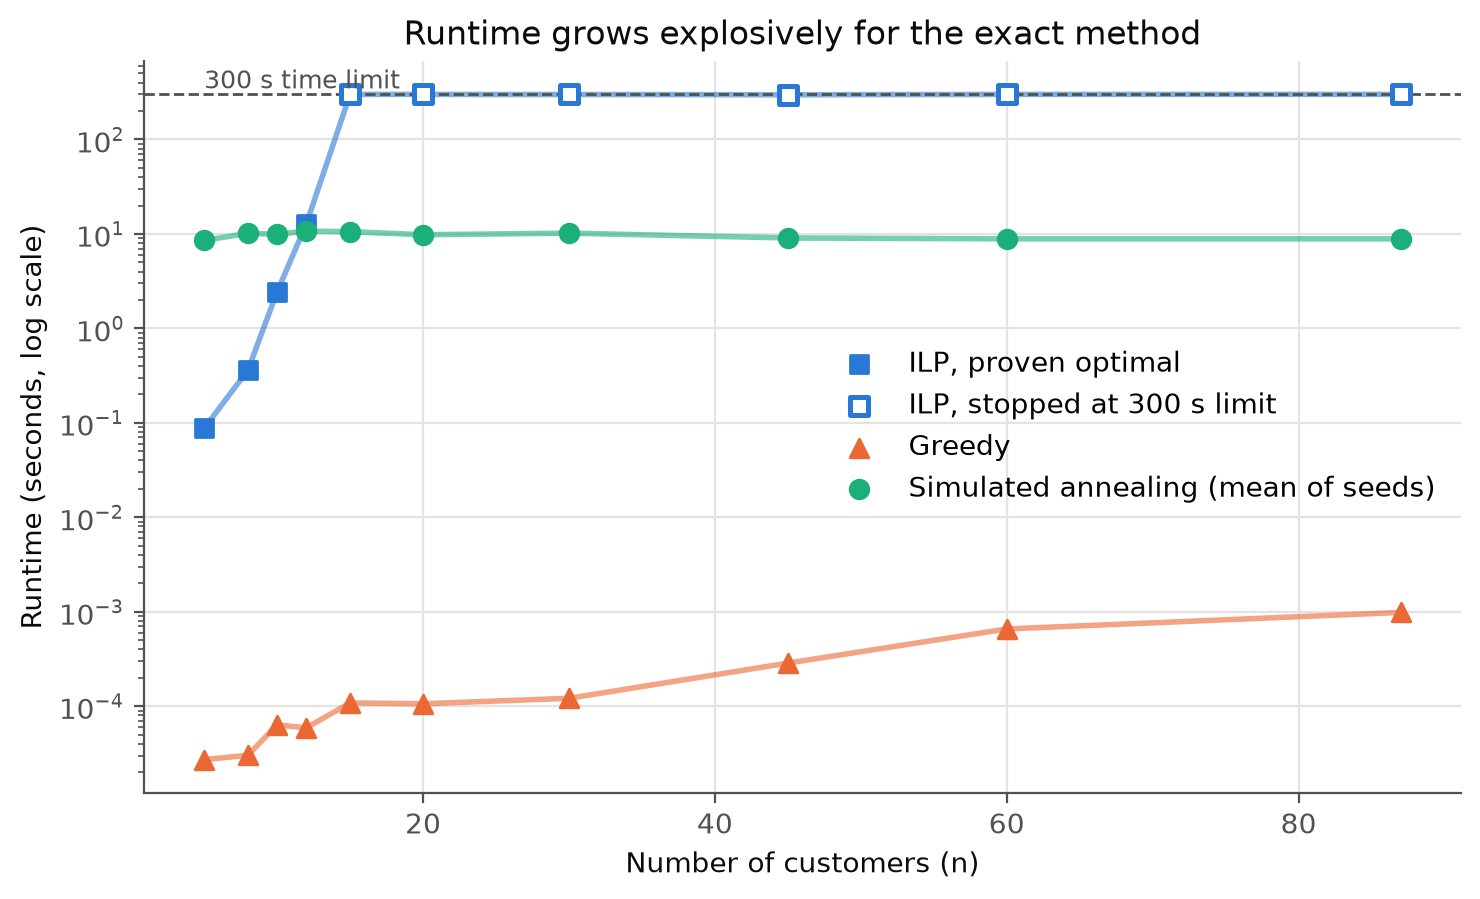

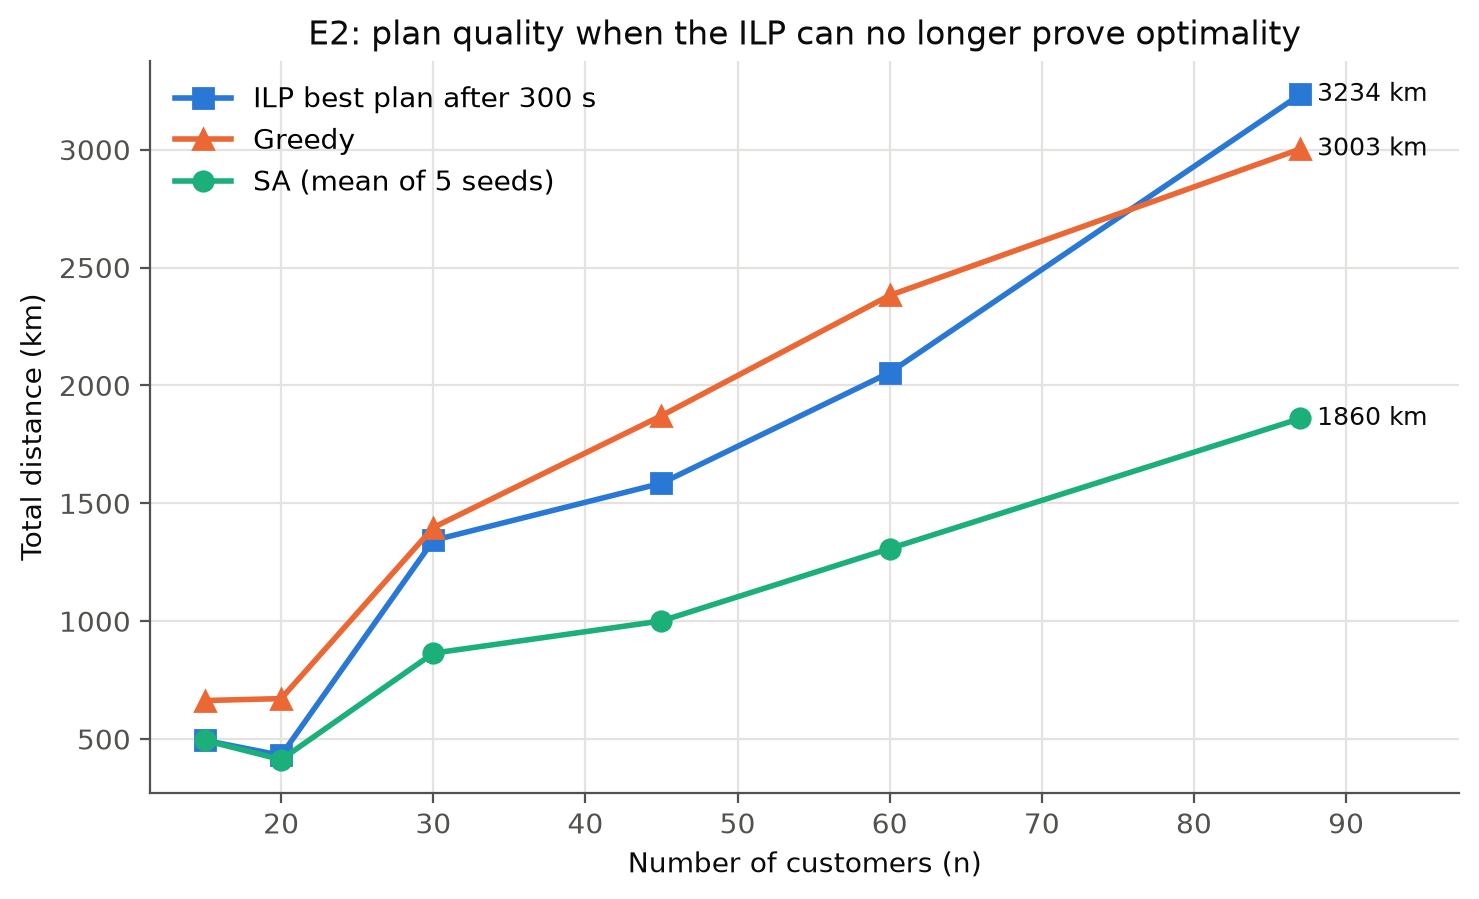

In [10]:
e2 = pd.read_csv(TABLES / "e2_summary.csv")
display(e2[["instance", "ilp_status", "ilp_km", "ilp_lower_bound_km", "ilp_time_s",
            "greedy_km", "sa_mean_km", "sa_best_km", "sa_mean_time_s"]].round(2))
display(Image(FIGURES / "f4_runtime_vs_size.png", width=750))
display(Image(FIGURES / "f5_distance_vs_size.png", width=750))

**Reading the lower bound carefully.** When the ILP stops at the time limit, the true optimum lies somewhere between
its lower bound and the best plan found. The bound from the MTZ formulation is weak, so a large gap between SA and the
bound does *not* mean SA is far from optimal.

### E3: effect of van capacity (all 87 customers)

,instance,method,mean_distance,best_distance,std_distance,routes_min,min_routes_needed,max_volume_dm3,mean_runtime_s
0,all_87_Q600,Greedy,3784.87,3784.87,NaN,18,17,340.1,0.00
1,all_87_Q600,SA,2734.43,2702.98,24.73,17,17,359.7,7.93
2,all_87_Q1000,Greedy,3002.94,3002.94,NaN,11,11,540.5,0.00
3,all_87_Q1000,SA,1858.62,1836.81,15.65,11,11,578.8,8.78
4,all_87_Q1500,Greedy,1892.52,1892.52,NaN,7,7,797.2,0.00
5,all_87_Q1500,SA,1458.25,1414.34,32.08,7,7,819.8,10.59


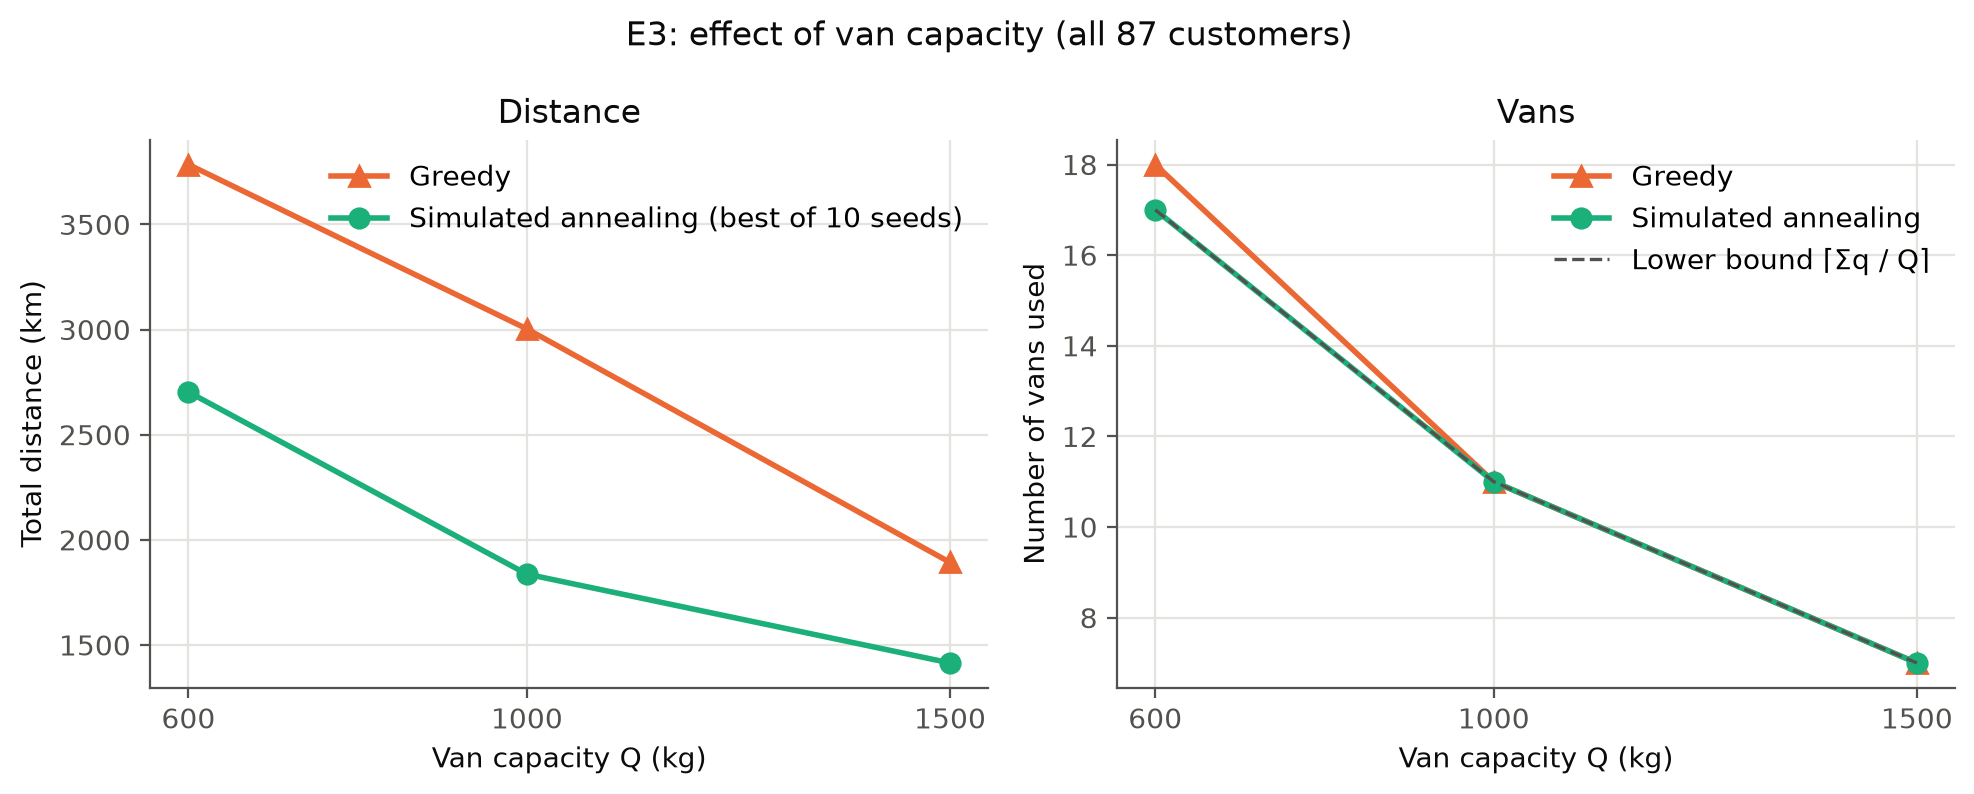

In [11]:
e35 = pd.read_csv(TABLES / "e3_e5_summary.csv")
e3 = e35[e35["experiment"] == "E3"]
display(e3[["instance", "method", "mean_distance", "best_distance", "std_distance", "routes_min",
            "min_routes_needed", "max_volume_dm3", "mean_runtime_s"]].round(2))
display(Image(FIGURES / "f9_capacity_sensitivity.png", width=850))

### E4: SA robustness across seeds and convergence

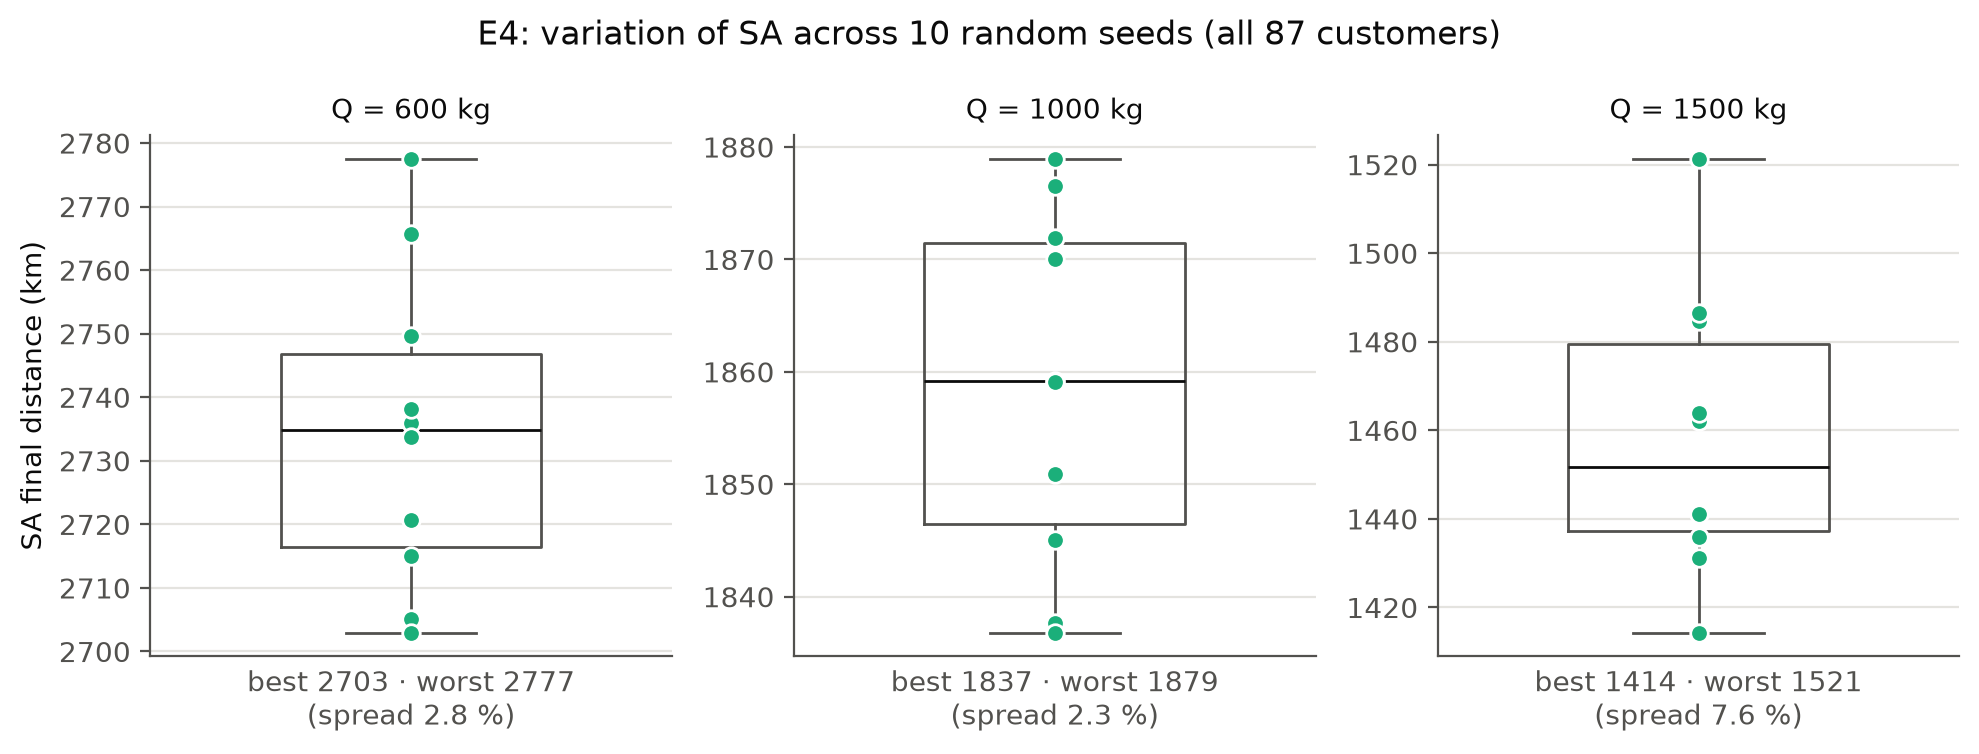

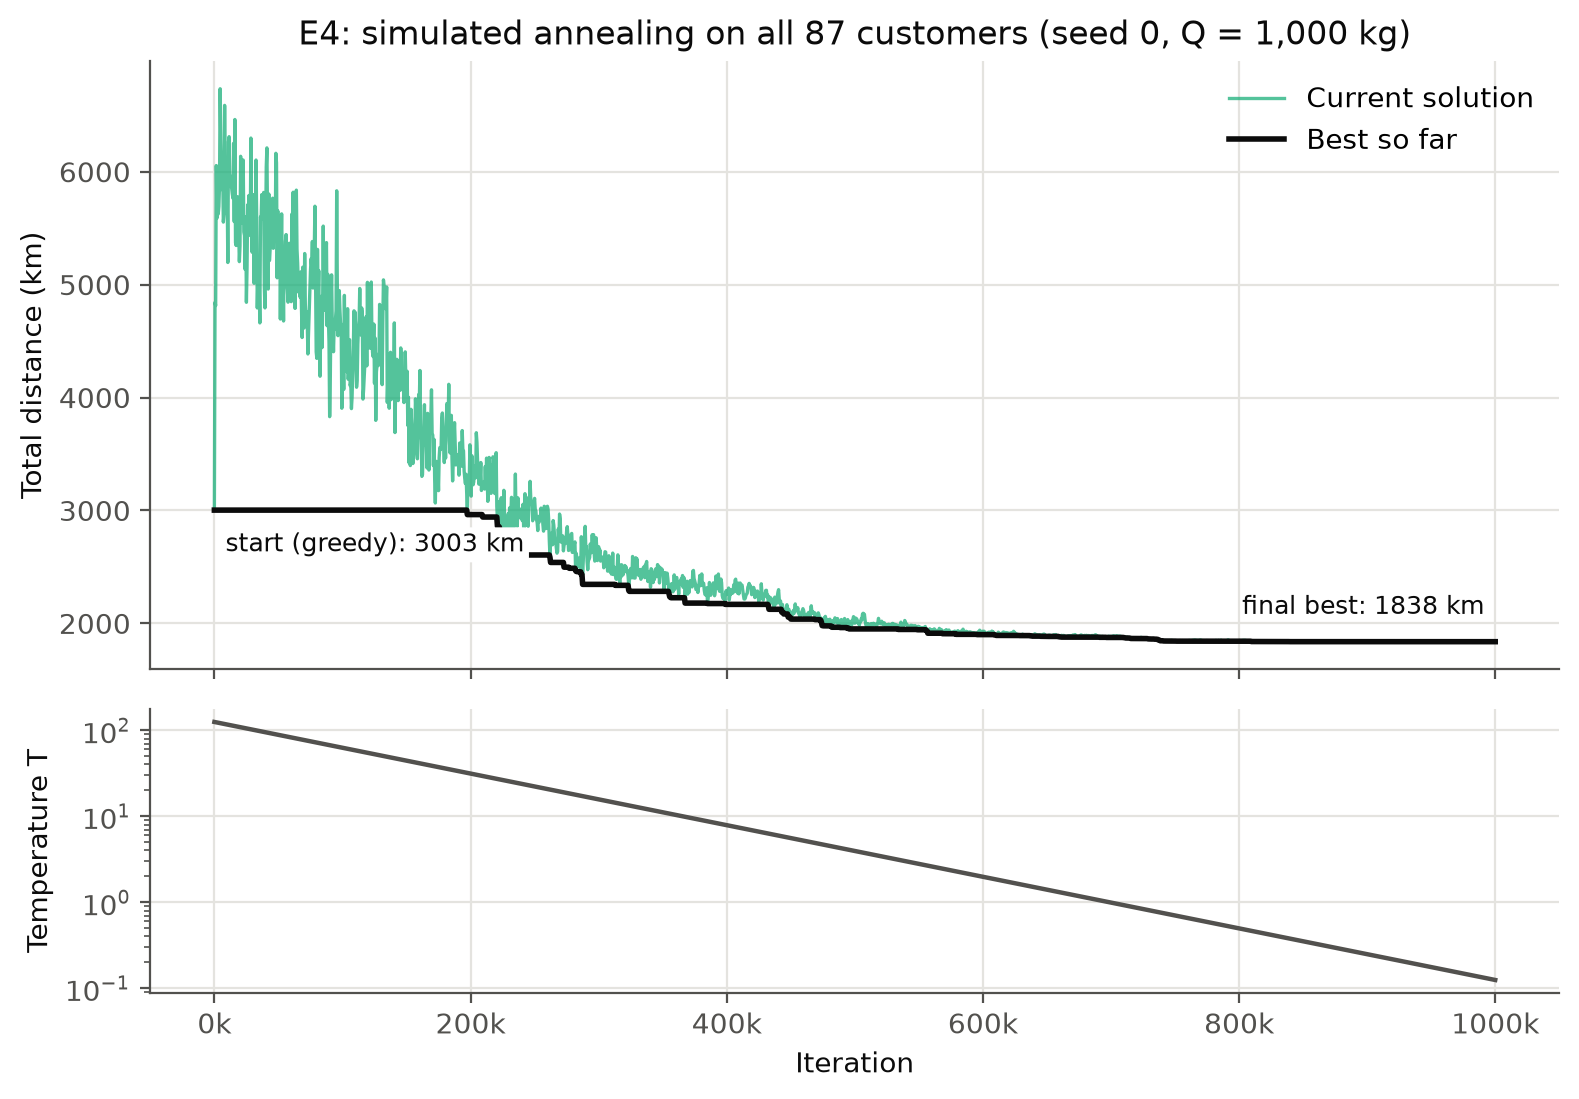

In [12]:
display(Image(FIGURES / "f8_sa_seed_spread.png", width=850))
display(Image(FIGURES / "f7_sa_convergence.png", width=750))

### E5: external benchmark A-n32-k5 (published optimum 784)

,method,runs,mean_distance,best_distance,worst_distance,mean_gap_to_optimum_pct,runs_at_optimum,mean_runtime_s
6,ILP,1,1178.0,1178.0,1178.0,50.26,NaN,299.40
7,Greedy,1,1145.0,1145.0,1145.0,46.05,NaN,0.00
8,SA,10,807.2,784.0,829.0,2.96,4.0,6.74


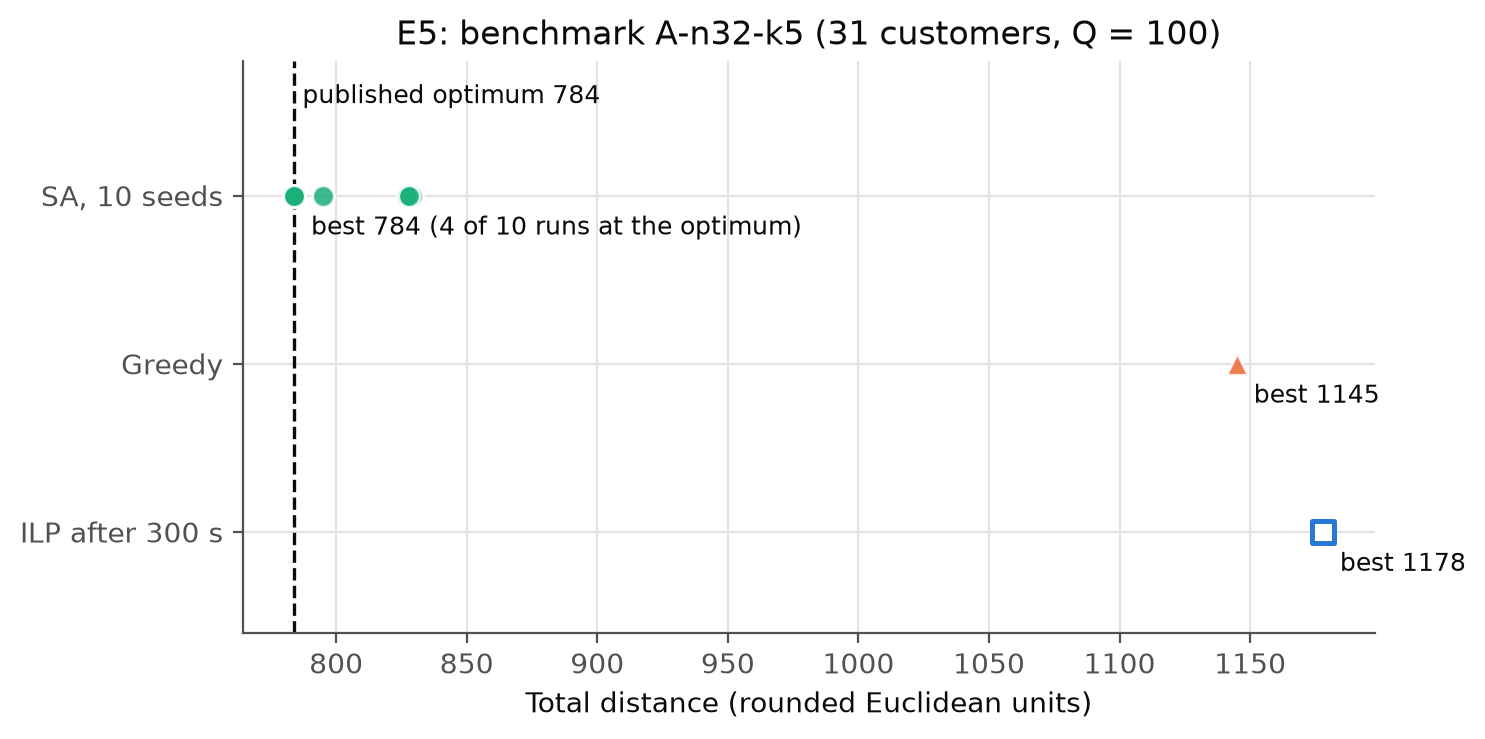

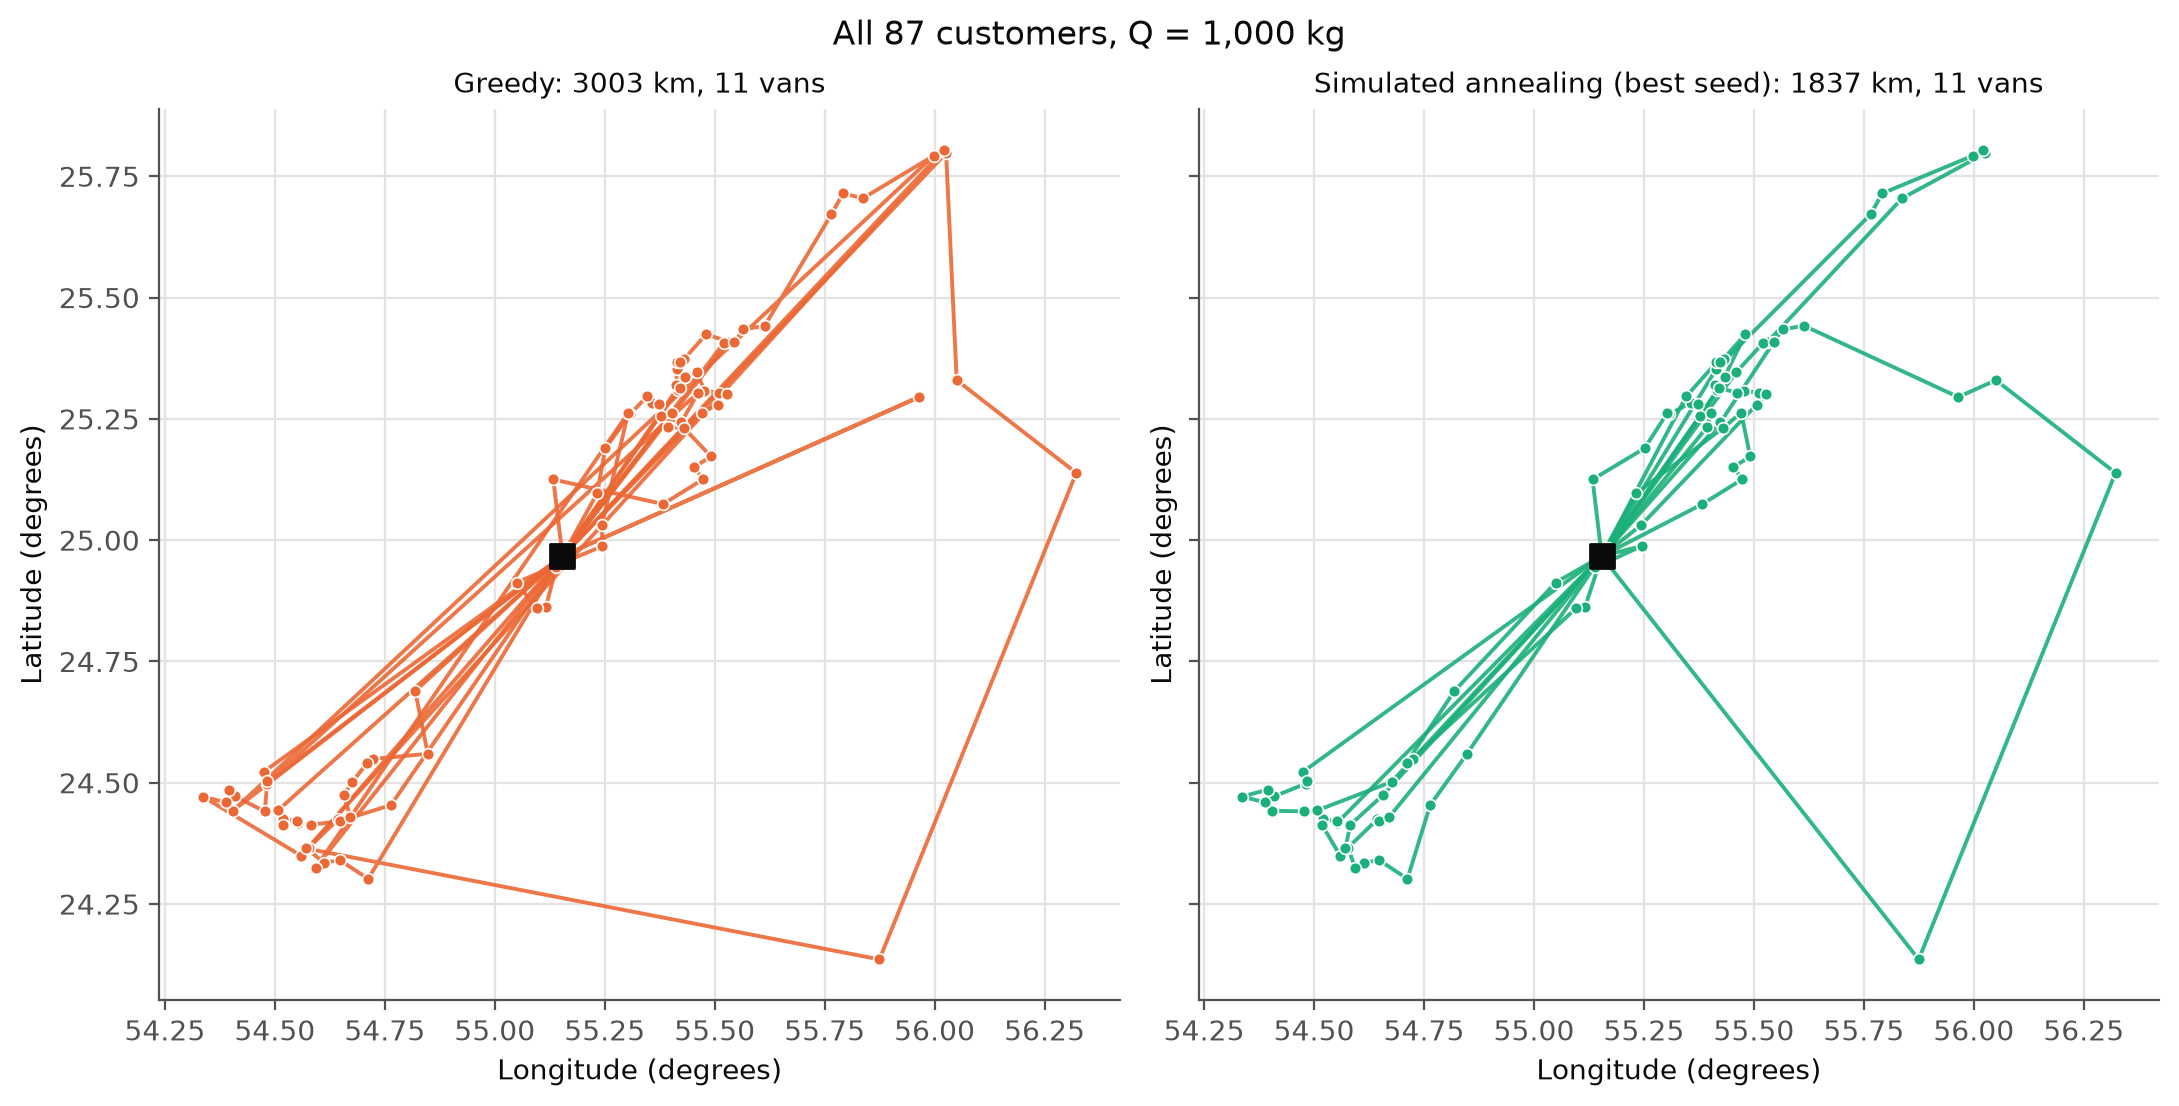

In [13]:
e5 = e35[e35["experiment"] == "E5"]
display(e5[["method", "runs", "mean_distance", "best_distance", "worst_distance", "mean_gap_to_optimum_pct",
            "runs_at_optimum", "mean_runtime_s"]].round(2))
display(Image(FIGURES / "f10_benchmark.png", width=750))
display(Image(FIGURES / "f11_routes_all87_greedy_vs_sa.png", width=850))

## Summary

- **Greedy** is almost instant and always feasible, but its plans were up to about 94 % longer than the optimum on small instances.
- **Simulated annealing** reached the proven optimum in every E1 run, and the published optimum of A-n32-k5 in 4 of 10 runs
  (mean 3 % above it), in about 10 seconds per run.
- **The exact ILP** proves optimality on small instances but could not do so from 15 customers within 300 s; at larger sizes
  SA's plans were much shorter than the ILP's best plan.
- SA's results vary by a few percent between seeds, so we report the mean and spread over several seeds, not a single run.